<a href="https://colab.research.google.com/github/starlight-5/GolfGame/blob/master/ex02_transform_tiefighter_%EC%88%98%EC%A0%95%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [402]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [403]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [404]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [405]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

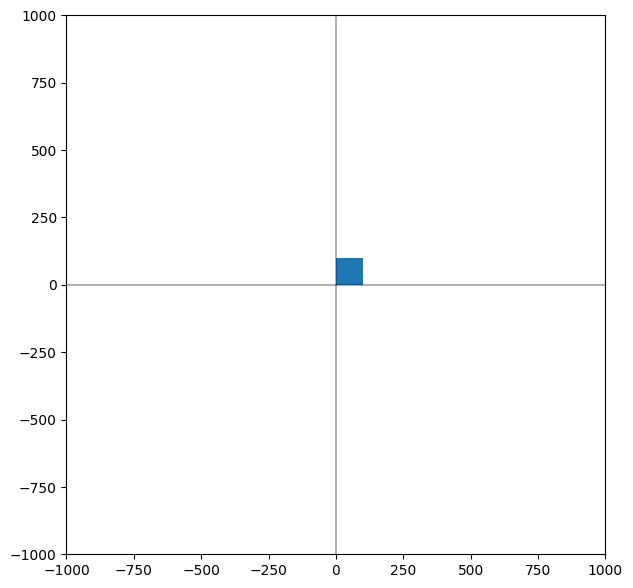

In [406]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [407]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0],
                 p[1],
                 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx],
                [0.0, 1.0, dy],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],
                q[1]])
  return q
def rotate(p, theta):
   # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0],
                 p[1],
                 1.0])
  # 2. 회전 변환 행렬 생성
  m = np.array([[np.cos(theta), -np.sin( theta), 0.0],
                [np.sin(theta), np.cos(theta), 0.0],
                [0.0, 0.0, 1.0]])
  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],
                q[1]])
  return q

def scale(p, sx, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0],
                 p[1],
                 1.0])

  # 2. 크기 변환 행렬 생성
  m = np.array([[sx, 0.0, 0],
                [0.0, sy, 0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)


  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],
                q[1]])
  return q
def shear_x(p, sx):
# 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0],
                 p[1],
                 1.0])

  # 2. 기울기 변환 행렬 생성
  m = np.array([[1.0, sx, 0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],
                q[1]])
  return q

def shear_y(p, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0],
                 p[1],
                 1.0])

  # 2. 기울기 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0],
              [sy,  1.0, 0.0],
              [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],
                q[1]])
  return q
def reflect_x(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0],
                 p[1],
                 1.0])

  # 2. x축 대칭 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0],
                [0.0, -1.0, 0.0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],
                q[1]])
  return q
def reflect_y(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0],
                 p[1],
                 1.0])

  # 2. y축 대칭 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0],
                q[1]])
  return q

def reflect_origin(p):
  # 원점 대칭
  return scale(p, -1.0, -1.0)

def reflect_yx(p):
  # y=x 대칭
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[0.0, 1.0, 0.0],
                [1.0, 0.0, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])


#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [408]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 사각형의 중심을 원점으로 이동
  pts = [translate(p, -LEN/2, -LEN/2) for p in (p1,p2,p3,p4)]
  # 크기 변환 후 45도 회전
  s = 5
  pts = [rotate(scale(p, s, s), np.pi/4)for p in pts]

  # 그리기
  draw_rectangle(ax,*pts)


In [409]:
def draw_right_arm(ax, p1, p2, p3, p4):  # 오른쪽 날개축
  # 중심을 원점으로 옮긴 뒤 가로로 길고 얇게 변환
  ptsUp = [translate(p, -LEN/2, -LEN/2) for p in (p1, p2, p3, p4)]
  ptsUp = [scale(p, 7.0, 0.6) for p in ptsUp]
  # -11.25도 회전
  ptsUp = [rotate(p, -np.pi/24) for p in ptsUp]

  # 원하는 모양 나온 후 오른쪽 위로으로 위치 조정후 그리기
  ptsUp = [translate(p, 450.0, 35.0) for p in ptsUp]
  draw_rectangle(ax, *ptsUp)

  # 아래쪽은 먼저 만든 위쪽을 x축 대칭해서 만들고 그리기
  ptsDown = [reflect_x(p) for p in ptsUp]
  draw_rectangle(ax, *ptsDown)



def draw_left_arm(ax, p1, p2, p3, p4):  # 왼쪽 날개축
  # 중심을 원점으로 옮긴 뒤 가로로 길고 얇게 변환
  ptsUp = [translate(p, -LEN/2, -LEN/2) for p in (p1, p2, p3, p4)]
  ptsUp = [scale(p, 7.0, 0.6) for p in ptsUp]
  # 11.25도 회전
  ptsUp = [rotate(p, np.pi/24) for p in ptsUp]
  # 원하는 모양 나온 후 위치 왼쪽 위로 으로 조정후 그리기
  ptsUp = [translate(p, -450.0, 35.0) for p in ptsUp]
  draw_rectangle(ax, *ptsUp)
  # 아래쪽은 먼저 만든 위쪽을 x축 대칭해서 만들고 그리기
  ptsDown = [reflect_x(p) for p in ptsUp]
  draw_rectangle(ax, *ptsDown)


In [410]:
def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개
  # 세로로 긴 사각형 원점에서 만들기
  pts = [translate(p, -LEN/2, -LEN/2) for p in (p1, p2, p3, p4)]
  # print(f"변환전: {pts}")
  pts = [scale(p, 1.0, 12.0) for p in pts]

  # p1,p4점만 x축으로 가까이 오도록 위치 변경
  dot0 = [translate(p, 1.0,160) for p in [(pts[0])]]
  dot3 = [translate(p, 1.0,-160) for p in [(pts[3])]]
  # print(f"p1: {dot0}")
  # print(f"p2: {dot3}")
  pts[0] = dot0[0]
  pts[3] = dot3[0]
  # print(f"변환후: {pts}")

  #원점에서 오른쪽으로 적당한 위치로 이동후 그리기
  pts = [translate(p,750,1)for p in pts]
  draw_rectangle(ax, *pts)


def draw_left_wing(ax, p1, p2, p3, p4):  # 왼쪽 날개
  # 세로로 긴 사각형 원점에서 만들기
  pts = [translate(p, -LEN/2, -LEN/2) for p in (p1, p2, p3, p4)]
  # print(f"변환전: {pts}")
  pts = [scale(p, 1.0, 12.0) for p in pts]

  # p1,p4점만 x축으로 가까이 오도록 위치 변경
  dot1 = [translate(p, 1.0,160.0) for p in [(pts[1])]]
  dot2 = [translate(p, 1.0,-160.0) for p in [(pts[2])]]
  # print(f"p1: {dot0}")
  # print(f"p2: {dot3}")
  pts[1] = dot1[0]
  pts[2] = dot2[0]
  # print(f"변환후: {pts}")

  #원점에서 왼쪽으로 적당한 위치로 이동후 그리기
  pts = [translate(p,-750,1.0)for p in pts]
  draw_rectangle(ax, *pts)


def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석
  draw_cockpit(ax, p1, p2, p3, p4)
  # 2~5. 왼쪽/오른쪽 날개축과 날개
  draw_left_arm(ax, p1, p2, p3, p4)
  draw_left_wing(ax, p1, p2, p3, p4)
  draw_right_arm(ax, p1, p2, p3, p4)
  draw_right_wing(ax, p1, p2, p3, p4)


### 3. main

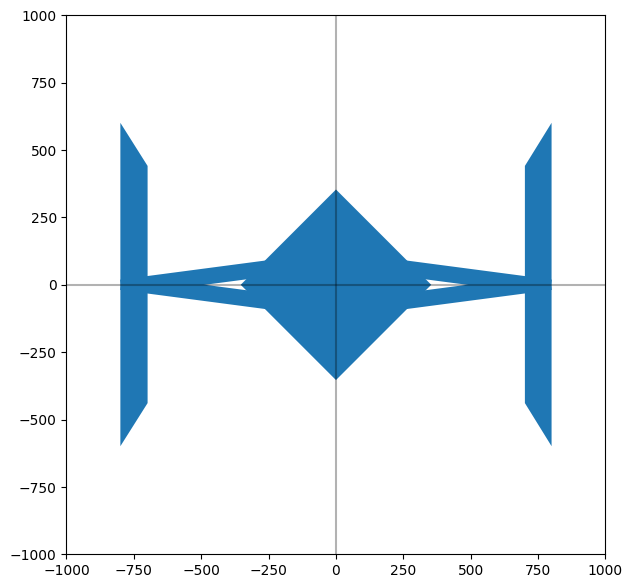

In [411]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()